# AI & Machine Learning

## Notebook Setup

In [55]:
# Do not run before reading readme.md file
import tensorflow as tf, cv2, sklearn, tf_keras_vis
print("versions: tf:", tf.__version__, "  cv2:", cv2.__version__, "  sk:", sklearn.__version__)

versions: tf: 2.21.0   cv2: 5.0.0   sk: 1.9.1


## Create your dataset

### Colab setup

In [2]:
from bing_image_downloader import downloader


import os

### Classes & dataset setup

In [3]:
import cv2
import os
import pandas as pd
from glob import glob
import matplotlib.pyplot as plt

import PIL
import PIL.Image

import numpy as np
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import RandomFlip, RandomRotation, RandomZoom, Rescaling, Resizing
from tensorflow.keras.preprocessing.image import img_to_array, load_img

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.optimizers import RMSprop
from tensorflow.keras.losses import SparseCategoricalCrossentropy
from tensorflow.keras import Model
from tensorflow.keras.layers import (
    GlobalAveragePooling2D,
    Dense,
    Dropout
)

from sklearn.model_selection import KFold
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as pl

import sklearn.metrics as me

from matplotlib import pyplot as plt
from matplotlib import cm
from tf_keras_vis.gradcam_plus_plus import GradcamPlusPlus
from tf_keras_vis.utils.model_modifiers import ReplaceToLinear
from tf_keras_vis.utils.scores import CategoricalScore

1) Choose which classes you would like to add.

In [6]:
classes = ["chiens", "chats"] # should be the same as folder names

2) Create a dataset with your own photos

In [17]:
def download_queries(queries, path, nbr):
    for query in queries:
        folder = os.path.join(path, query)
        os.makedirs(folder, exist_ok=True)

        missing = nbr - len(os.listdir(folder))
        if missing <= 0:
            print(f"{folder} : déjà {nbr} images ou plus, rien à télécharger.")
            continue

        print(f"{folder} : téléchargement de {missing} image(s)...")
        downloader.download(
            query, limit=missing, output_dir=path,
            adult_filter_off=False, force_replace=False, timeout=15
        )

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

def upload_pictures(path):
    # Crée le dossier s'il n'existe pas encore
    os.makedirs(path, exist_ok=True)

    # Compte les images déjà présentes
    images = [f for f in os.listdir(path) if f.lower().endswith(IMAGE_EXTENSIONS)]

    if images:
        print(f"  {len(images)} image(s) trouvée(s) dans {path}")
    else:
        print(f"  ⚠️ Aucune image dans {path} : ajoutez-y vos images puis relancez la cellule.")

In [14]:
for train_class in classes:
  print("for", train_class, "import training pictures:")
  upload_pictures('dataset_train/' + train_class)
  print("for", train_class, "import test pictures:")
  upload_pictures('dataset_test/' + train_class)

for chiens import training pictures:
  5 image(s) trouvée(s) dans dataset_train/chiens
for chiens import test pictures:
  2 image(s) trouvée(s) dans dataset_test/chiens
for chats import training pictures:
  7 image(s) trouvée(s) dans dataset_train/chats
for chats import test pictures:
  2 image(s) trouvée(s) dans dataset_test/chats


If necessary (not enough images), execute the following cell with the needed class names in the QUERRIES variable.

In [19]:
QUERIES = [classes[0]]  # for example, with enought images for dogs, and a need for cat

NBR = int(len(os.listdir("dataset_train/" + str(classes[1]))))
download_queries(QUERIES, "dataset_train", NBR)
download_queries(QUERIES, "dataset_test", int(max(int(NBR/4), 1)))

dataset_train\chiens : téléchargement de 2 image(s)...


[!!]Indexing page: 1

[%] Indexed 2 Images on Page 1.


[%] Downloading Image #1 from https://chien-infos.com/wp-content/uploads/2021/06/top20-chiens.jpg
[%] File Downloaded !

[%] Downloading Image #2 from https://cdn0.toutcomment.com/fr/posts/1/0/9/races_de_chiens_les_plus_populaires_15901_orig.jpg
[%] File Downloaded !

dataset_test\chiens : déjà 1 images ou plus, rien à télécharger.


Or to complet the set use the next cell: (won't work for personnal pictures)

In [ ]:
# QUERIES = classes.copy()

# NBR = 30
# download_queries(QUERIES, "dataset_train", NBR)
# download_queries(QUERIES, "dataset_test", int(max(int(NBR/4), 1)))

In [20]:
#png to jpg
def png_to_jpg(path):
    nbrOfPng = 0

    for label_dir in os.listdir(path):
        if os.path.isfile(label_dir):
            continue

        label_path_path = os.path.join(path, label_dir)

        for photoName in os.listdir(label_path_path):
            if (photoName.rsplit('.',1)[1] == "png") :
                old_path = os.path.join(label_path_path, photoName)
                new_path = old_path.rsplit('.',1)[0] + ".jpg"

                png_img = cv2.imread(old_path)
                cv2.imwrite(new_path, png_img, [int(cv2.IMWRITE_JPEG_QUALITY), 100])
                os.remove(old_path) # remove previous image
                nbrOfPng += 1
    print("number of png found and resized in jpg : " + str(nbrOfPng))

png_to_jpg("dataset_train")
png_to_jpg("dataset_test")

number of png found and resized in jpg : 0
number of png found and resized in jpg : 1


3) Separate your dataset into train and test subsets.

In [21]:
# def create_dataframe_from_directories(path):
#     data = []

#     for label_dir in os.listdir(path):
#         if os.path.isfile(label_dir):
#             continue

#         label_path_path = os.path.join(path, label_dir)
#         for file in os.listdir(label_path_path):
#             data.append([os.path.join(label_path_path, file), label_dir])

#     return pd.DataFrame(data, columns = ["path", "label"])

def create_dataframe_from_directories(path):
    data = []
    image_extensions = ('.jpg', '.jpeg', '.png', '.gif', '.bmp')

    for label_dir in os.listdir(path):
        label_path = os.path.join(path, label_dir)

        # Ensure it's a directory before processing as a label
        if os.path.isdir(label_path):
            for file_name in os.listdir(label_path):
                file_path = os.path.join(label_path, file_name)
                # Ensure it's a file and has a valid image extension
                if os.path.isfile(file_path) and file_name.lower().endswith(image_extensions):
                    data.append([file_path, label_dir])

    return pd.DataFrame(data, columns = ["path", "label"])

In [22]:
train_df = create_dataframe_from_directories("dataset_train")
test_df = create_dataframe_from_directories("dataset_test")

In [23]:
# Initialize and fit LabelEncoder on unique training labels to determine a consistent order
label_encoder_for_names = LabelEncoder()
label_encoder_for_names.fit(train_df['label'].unique())

# Update LABEL_NAMES to reflect the alphabetically sorted order used by LabelEncoder
LABEL_NAMES = label_encoder_for_names.classes_
print(f"LABEL_NAMES: {LABEL_NAMES}")

# LABEL_NAMES = pd.unique(train_df['label'])
# LABEL_NAMES

LABEL_NAMES: ['chats' 'chiens']


Display some images of our dataset

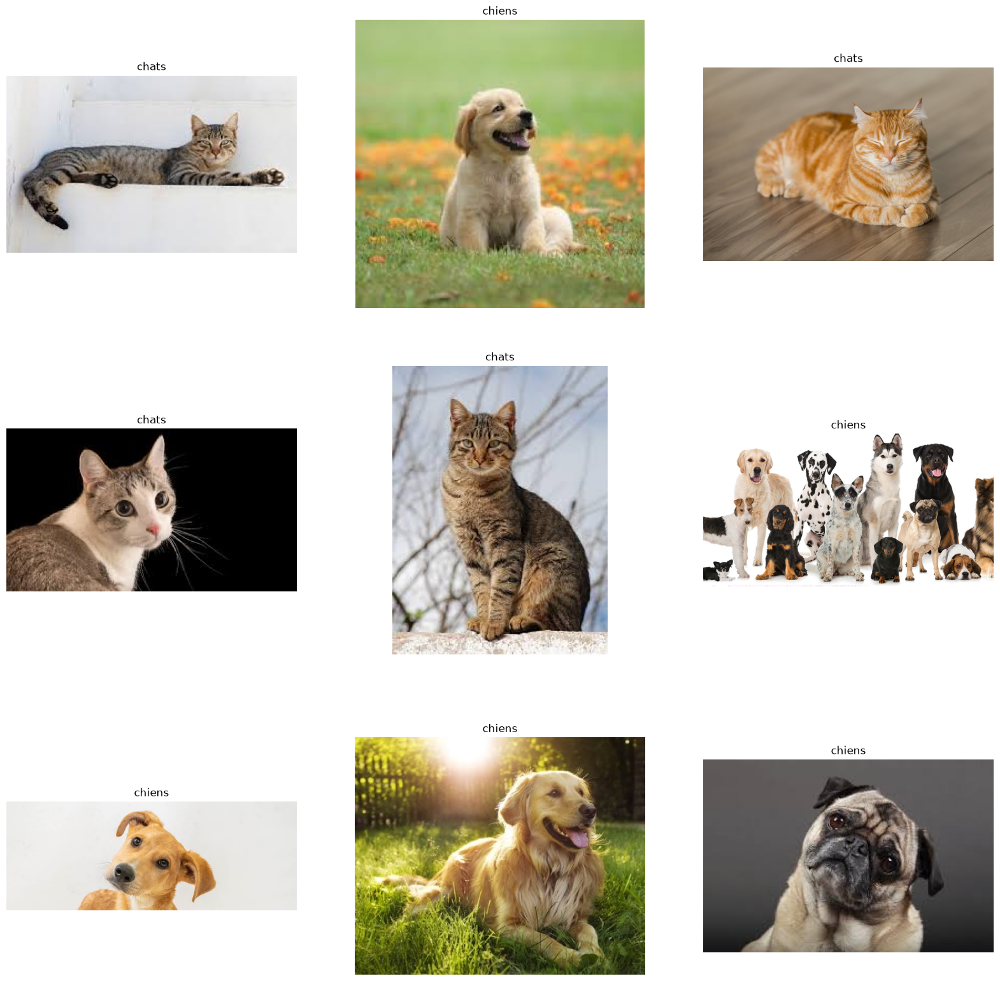

In [24]:
plt.figure(figsize=(20, 20))

i = 0
for _, rowdata in train_df.sample(frac=1).head(9).iterrows():
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(PIL.Image.open(rowdata.path))
    plt.title(rowdata.label)
    plt.axis("off")
    i += 1

## Explore your dataset

Count the number of examples per classes and plot an histogram of it

In [26]:
def create_histogram_counts(data, histogram_title):
  counts = data['label'].value_counts()
  print(counts)
  plt.figure(figsize=(10, 6))
  plt.bar(counts.index, counts.values)
  plt.xlabel('Class')
  plt.ylabel('Count')
  plt.title(histogram_title)
  plt.xticks(rotation=45)
  plt.show()
  print()

label
chats     7
chiens    7
Name: count, dtype: int64


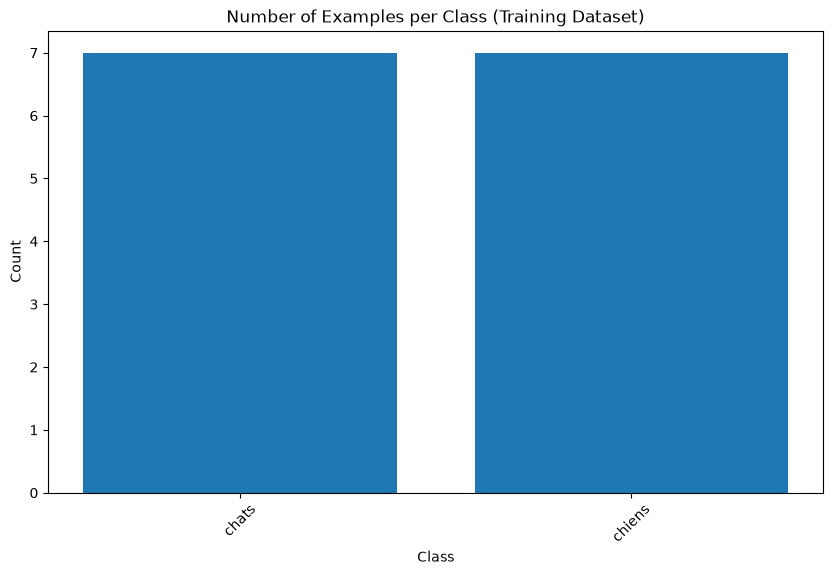


label
chats     2
chiens    2
Name: count, dtype: int64


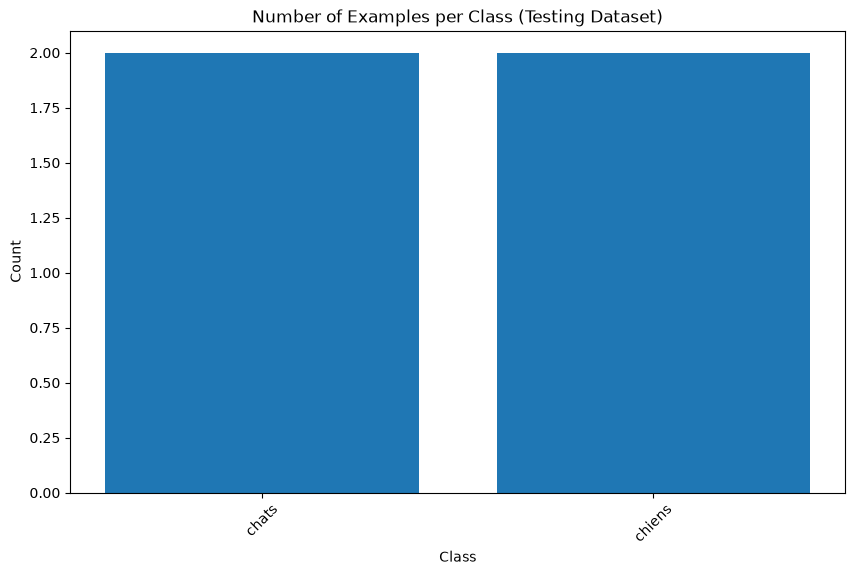

In [27]:
create_histogram_counts(train_df, "Number of Examples per Class (Training Dataset)")
create_histogram_counts(test_df, "Number of Examples per Class (Testing Dataset)")

## Preprocessing steps

In [28]:
IMG_HEIGHT = 224
IMG_WIDTH = 224

image_preprocesses = Sequential([
    Resizing(IMG_HEIGHT, IMG_WIDTH, crop_to_aspect_ratio=True),
    Rescaling(1. / 255)
])

image_augmentations = Sequential([
    RandomFlip(mode='horizontal'),  # Randomly flip images horizontally
    RandomRotation(factor=0.2),  # Randomly rotate images by a maximum of 20 degrees
    RandomZoom(height_factor=0.2, width_factor=0.2)  # Randomly zoom images by a maximum of 20% in height and width
])

def open_images(paths):
    return np.stack([
        open_image(path) for path in paths
    ])

def open_image(path):
    with PIL.Image.open(path) as image:
        opened_img = image_preprocesses(np.asarray(image))

    return opened_img

def augment_images(images):
    return np.stack([
        image_augmentations(img) for img in images
    ])

Plot examples of preprocessed and augmented images

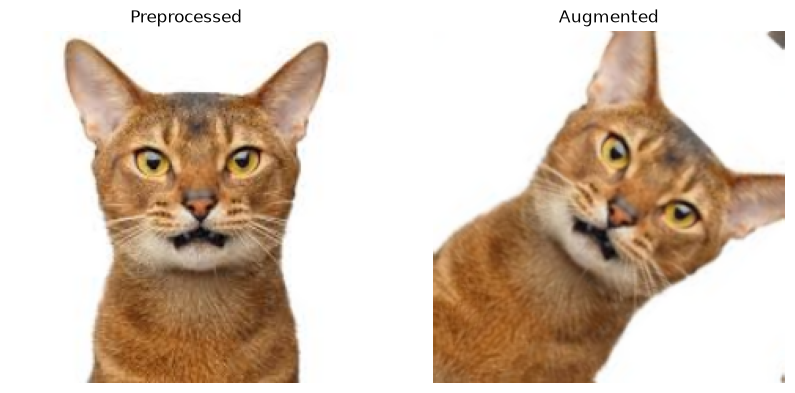

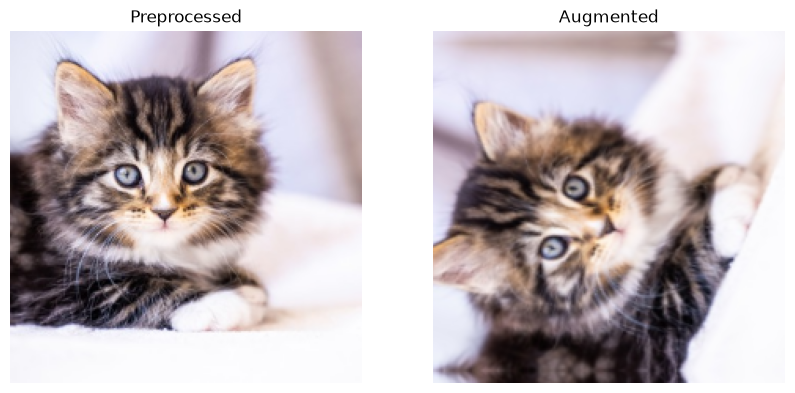

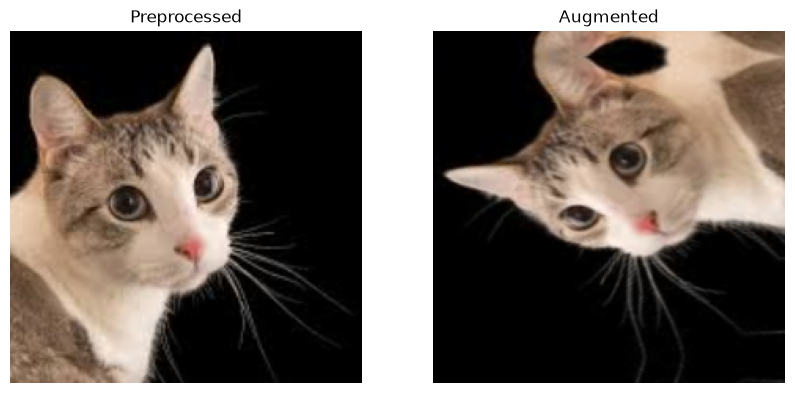

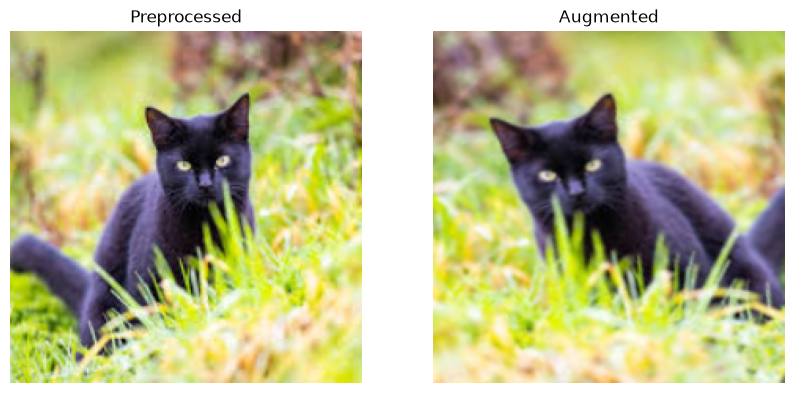

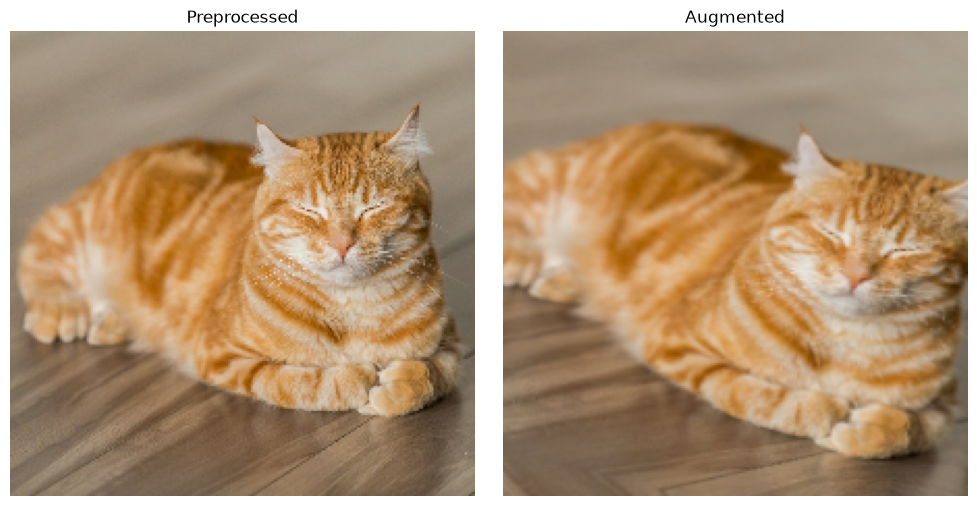

In [29]:
for i in range(5):
  image_path = train_df['path'].iloc[i]
  image = open_image(image_path)
  augmented_image = augment_images([image])

  fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 5))
  axes[0].imshow(image)
  axes[0].set_title('Preprocessed')
  axes[0].axis('off')
  axes[1].imshow(augmented_image[0])
  axes[1].set_title('Augmented')
  axes[1].axis('off')

plt.tight_layout()
plt.show()

## Define model

In [30]:
def get_model():
    base_model = MobileNetV2(
        input_shape=(224, 224, 3),
        weights='imagenet',
        include_top=False
    )

    layers = base_model.output

    added_layers = [
        # important, we need global average pooling instead of flatten for class activation map later on
        GlobalAveragePooling2D(),
        Dense(512, activation='relu'),
        Dropout(0.2),
        Dense(256, activation='relu'),
        Dense(len(LABEL_NAMES), activation='softmax')
    ]

    model = Model(inputs=base_model.input, outputs=Sequential(added_layers)(layers))

    for layer in base_model.layers:
        layer.trainable = False

    model.compile(
      optimizer = RMSprop(),
      loss = SparseCategoricalCrossentropy(),
      metrics = ['acc']
    )

    return model

In [32]:
#get_model().summary()

## Model training

Cross-validation

**NOTE**: you shouldn't augment validations images. What we want to evaluate is the performances on "real" images, not on images that are augmented and change all the time

In [33]:
# Hyper param:
rdm_state = 1234

NB_EPOCHS = 16
BATCH_SIZE = 14

In [34]:
shuffled_dataset = train_df.sample(frac=1, random_state=rdm_state).reset_index(drop=True)

# Filter out rows where 'path' is a directory before splitting
filtered_shuffled_dataset = shuffled_dataset[shuffled_dataset['path'].apply(os.path.isfile)]

dataset_paths = filtered_shuffled_dataset['path'].to_numpy()
dataset_labels = filtered_shuffled_dataset['label'].to_numpy()

total_train_paths, test_paths, total_train_labels, test_labels = train_test_split(
    dataset_paths, dataset_labels, test_size=0.2, random_state=rdm_state
)

# We need to convert from string labels to integers
label_encoder = LabelEncoder()
# Fit on the unique labels from the filtered dataset to ensure all potential labels are covered.
label_encoder.fit(pd.unique(filtered_shuffled_dataset['label']))
total_train_labels = label_encoder.transform(total_train_labels)
test_labels = label_encoder.transform(test_labels)


train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

# Augment images
total_images = open_images(total_train_paths)
total_images = np.concatenate((total_images,
                               augment_images(open_images(total_train_paths)),
                               augment_images(open_images(total_train_paths))),
                               axis=0)
total_labels_1 = total_train_labels
total_labels = np.append(total_labels_1, total_labels_1)
total_labels = np.append(total_labels, total_labels_1)


for train_index, val_index in KFold(n_splits=5).split(total_images, total_labels):

    # Corrected: val_images and val_labels should come from the KFold split of total_images/total_labels
    val_images = total_images[val_index]
    val_labels = total_labels[val_index]

    model = get_model() # We reinitialize the model

    history = model.fit(
        x=total_images[train_index],
        y=total_labels[train_index],
        batch_size=BATCH_SIZE,
        validation_data=[val_images, val_labels],
        epochs=NB_EPOCHS,
    )

    train_losses.append(history.history['loss'])
    val_losses.append(history.history['val_loss'])
    train_accuracies.append(history.history['acc'])
    val_accuracies.append(history.history['val_acc'])

Epoch 1/16
2/2 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step - acc: 0.6154 - loss: 1.2521 - val_acc: 0.5714 - val_loss: 1.8271
Epoch 2/16
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 285ms/step - acc: 0.6538 - loss: 2.8335 - val_acc: 1.0000 - val_loss: 0.0086
Epoch 3/16
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 351ms/step - acc: 0.9615 - loss: 0.0857 - val_acc: 1.0000 - val_loss: 0.0017
Epoch 4/16
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 285ms/step - acc: 1.0000 - loss: 0.0031 - val_acc: 1.0000 - val_loss: 0.0016
Epoch 5/16
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 272ms/step - acc: 1.0000 - loss: 0.0020 - val_acc: 1.0000 - val_loss: 0.0014
Epoch 6/16
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 272ms/step - acc: 1.0000 - loss: 0.0026 - val_acc: 1.0000 - val_loss: 0.0012
Epoch 7/16
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 280ms/step - acc: 1.0000 - loss: 0.0024 - val_acc: 1.0000 - val_loss: 0.0011
Epoch 8/16
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 287ms/step - acc: 1.0000 - loss: 0.0011 - val_acc: 1.0000 - val_loss: 0.0010
Epoch 9/16
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 283ms/step - acc: 1.0000 - loss: 0.0

## Results

Plot the results from your crossvalidation

In [35]:
def plot_kfold_mean_performance(ax, train_performances, val_performances, measure_name):
    train_mean = np.mean(train_performances, axis=0)
    val_mean = np.mean(val_performances, axis=0)
    train_sd = np.std(train_performances, axis=0)
    val_sd = np.std(val_performances, axis=0)

    ax.fill_between(np.arange(1, NB_EPOCHS + 1), train_mean, train_mean+train_sd, facecolor='blue', alpha=0.5, label='Train')
    ax.fill_between(np.arange(1, NB_EPOCHS + 1), train_mean, train_mean-train_sd, facecolor='blue', alpha=0.5)

    ax.fill_between(np.arange(1, NB_EPOCHS + 1), val_mean, val_mean+val_sd, facecolor='orange', alpha=0.5, label='Val')
    ax.fill_between(np.arange(1, NB_EPOCHS + 1), val_mean, val_mean-val_sd, facecolor='orange', alpha=0.5)

    ax.set_xticks(np.arange(1, NB_EPOCHS + 1))

    ax.set_ylabel(measure_name)
    ax.set_xlabel('Number of epochs')
    #pl.title(str(K)+'-fold CV with '+str(n)+' hidden neurons')
    ax.legend()
    ax.grid()

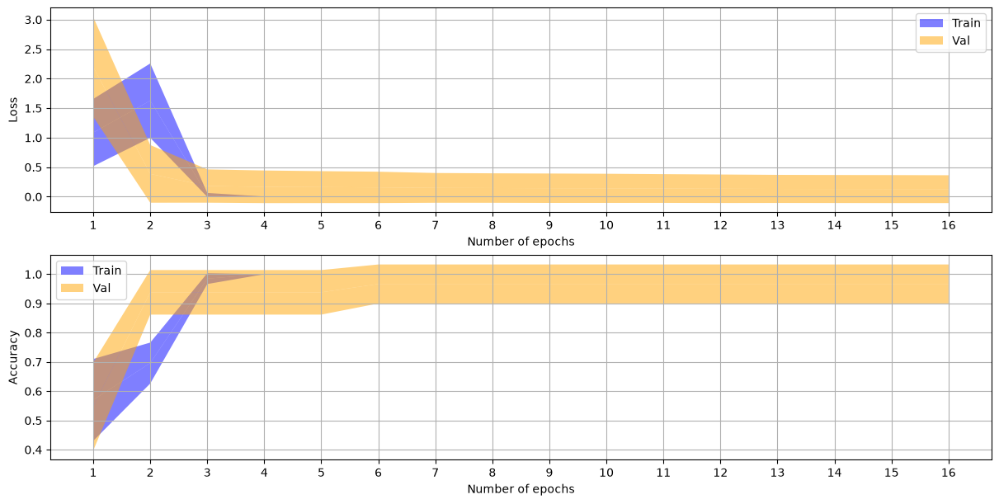

In [36]:
fig, axs = plt.subplots(2, 1, constrained_layout=True, figsize=(12,6))

plot_kfold_mean_performance(axs[0], train_losses, val_losses, "Loss")
plot_kfold_mean_performance(axs[1], train_accuracies, val_accuracies, "Accuracy")

## Evaluate model on test set

In [37]:
# First retrain model on all the training data
train_images = open_images(total_train_paths)
train_labels = total_train_labels

NB_EPOCHS = 14

model = get_model() # We reinitialize the model

history = model.fit(
    x=train_images,
    y=train_labels,
    batch_size=BATCH_SIZE,
    epochs=NB_EPOCHS,
)

Epoch 1/14
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step - acc: 0.6364 - loss: 0.6919
Epoch 2/14
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 195ms/step - acc: 1.0000 - loss: 0.0021
Epoch 3/14
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 198ms/step - acc: 1.0000 - loss: 0.0019
Epoch 4/14
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step - acc: 1.0000 - loss: 0.0012
Epoch 5/14
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - acc: 1.0000 - loss: 0.0022
Epoch 6/14
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 198ms/step - acc: 1.0000 - loss: 8.0602e-04
Epoch 7/14
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step - acc: 1.0000 - loss: 7.0079e-04
Epoch 8/14
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step - acc: 1.0000 - loss: 5.7216e-04
Epoch 9/14
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 198ms/step - acc: 1.0000 - loss: 7.8571e-04
Epoch 10/14
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 198ms/step - acc: 1.0000 - loss: 4.9449e-04
Epoch 11/14
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step - acc: 1.0000 - loss: 9.2552e-04
Epoch 12/14
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - acc: 1.0000 - loss: 5.7937e-04
Epoch 13/14
1/1 ━━━━━━━━

In [38]:
# Empty a bit the memory
import gc

del train_images
del train_labels
gc.collect()

32083

In [39]:
shuffled_dataset = test_df.sample(frac=1, random_state=1234).reset_index(drop=True) # random_state=6

# Filter out rows where 'path' is a directory before splitting
filtered_shuffled_dataset = shuffled_dataset[shuffled_dataset['path'].apply(os.path.isfile)]

#print(len(shuffled_dataset))

dataset_paths = filtered_shuffled_dataset['path'].to_numpy()
dataset_labels = filtered_shuffled_dataset['label'].to_numpy()


print(dataset_labels)
#LABEL_NAMES = pd.unique(dataset_labels)
print(LABEL_NAMES)

# We need to convert from string labels to integers
label_encoder = LabelEncoder()
label_encoder.fit(LABEL_NAMES) # Fit on the global LABEL_NAMES to ensure consistent mapping
test_labels = label_encoder.transform(dataset_labels)

test_images = open_images(dataset_paths)

pred = model.predict(test_images)
pred = np.argmax(pred, axis=-1)

test_confusion_matrix = me.confusion_matrix(test_labels, pred, labels=np.arange(len(LABEL_NAMES)))

['chats' 'chats' 'chiens' 'chiens']
['chats' 'chiens']
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


In [40]:
#F-score
dim = len(test_confusion_matrix)

for x in range(dim):
    col = 0
    lin = 0
    for y in range(dim) :
      if y != x :
        col += test_confusion_matrix[y][x]
        lin += test_confusion_matrix[x][y]

    TP = test_confusion_matrix[x][x]
    # Handle division by zero for precision and recall
    precision = TP / (TP + col) if (TP + col) != 0 else 0
    recall = TP / (TP + lin) if (TP + lin) != 0 else 0
    fScore = (2 * precision * recall) / (precision + recall) if (precision + recall) != 0 else 0
    print('F-Score', LABEL_NAMES[x].rjust(12), '(' + str(x) + ')', ':', fScore)

F-Score        chats (0) : 1.0
F-Score       chiens (1) : 1.0


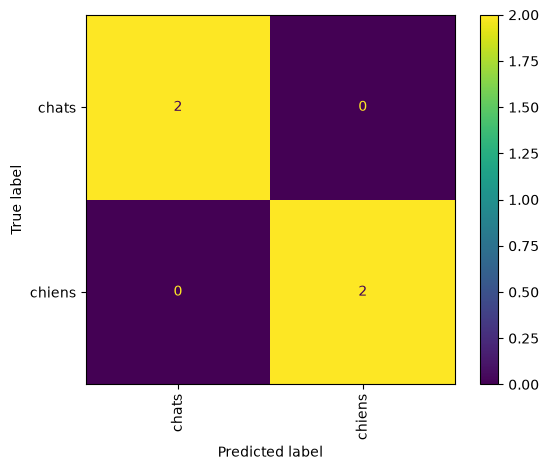

In [41]:
confusion_matrix_display = me.ConfusionMatrixDisplay(
    confusion_matrix=test_confusion_matrix,
    display_labels=LABEL_NAMES,
)

confusion_matrix_display.plot(xticks_rotation='vertical')
plt.show()

## Display some misclassified images

Display some misclassified images to be able to see what images are difficult for the model

In [42]:
mislabel_indices = np.where(test_labels != pred)[0] #!= for missclassified
plt.figure(figsize=(20, 20))

i = 0
rowOrCol = 3
#If we want to only have the nth first elements, use mislabel_indices[:n]
for index in mislabel_indices[:rowOrCol*rowOrCol]:
    ax = plt.subplot(rowOrCol, rowOrCol, i + 1)
    plt.imshow(test_images[index])
    plt.title("truth : " + LABEL_NAMES[test_labels[index]] + " predicted : " + LABEL_NAMES[pred[index]])
    plt.axis("off")
    i += 1

<Figure size 2000x2000 with 0 Axes>

## Use grad-cam to inspect how the model classify


Here we can see an heatmap of the regions that activates the model the most.

### For more information:
- tf-keras-vis documentation: https://keisen.github.io/tf-keras-vis-docs/
- Grad-cam paper: https://arxiv.org/pdf/1610.02391.pdf
- Grad-cam++ paper: https://arxiv.org/pdf/1710.11063.pdf

Display heat map gradient:

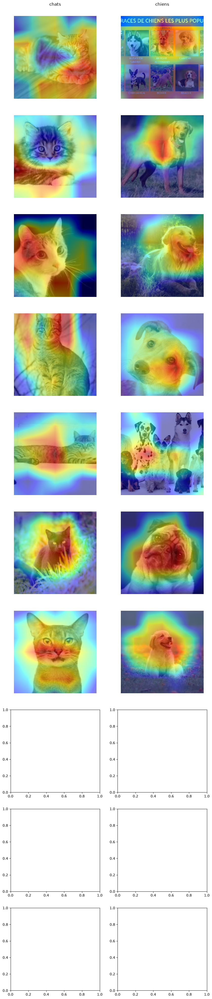

In [43]:
# Create GradCAM++ object
gradcam = GradcamPlusPlus(
    model,
    model_modifier=ReplaceToLinear(),
    clone=True,
)

nb_images_per_class = 10

fig, axs = plt.subplots(nb_images_per_class, len(LABEL_NAMES), figsize=(len(LABEL_NAMES) * 5, nb_images_per_class * 5))

for label_idx, label_name in enumerate(LABEL_NAMES):
    axs[0,label_idx].set_title(label_name, loc='center', y=1.1)

    i = 0
    for _, rowdata in train_df[train_df['label'] == label_name].sample(frac=1).head(nb_images_per_class).iterrows():
        img = open_image(rowdata.path)
        predGradCam = model(np.expand_dims(img, axis=0))

        # Generate cam with GradCAM++
        score = CategoricalScore(np.argmax(predGradCam))
        cam = gradcam(score, img)
        heatmap = np.uint8(cm.jet(cam[0])[..., :3] * 255)

        axs[i,label_idx].imshow(img, vmin=0, vmax=1)
        axs[i,label_idx].imshow(heatmap, cmap='jet', alpha=0.5) # overlay
        axs[i,label_idx].axis("off")

        i += 1

## Grad-cam on misclassified images

Now do the same than above, but with the misclassified images. You shouldn't change anything pertaining to grad-cam besides on which image and prediction you do it

In [44]:
# Create GradCAM++ object
gradcam = GradcamPlusPlus(
    model,
    model_modifier=ReplaceToLinear(),
    clone=True,
)

nb_images_per_class = 10


plt.figure(figsize=(20, 20))

i = 0
#If we want to only have the nth first elements, use mislabel_indices[:n]
for index in mislabel_indices[:rowOrCol*rowOrCol]:
    ax = plt.subplot(rowOrCol, rowOrCol, i + 1)

    # Generate cam with GradCAM++
    score = CategoricalScore(np.argmax(pred[index]))
    cam = gradcam(score, test_images[index])
    heatmap = np.uint8(cm.jet(cam[0])[..., :3] * 255)

    plt.imshow(test_images[index])
    plt.imshow(heatmap, cmap='jet', alpha=0.5) # overlay
    plt.title("truth : " + LABEL_NAMES[test_labels[index]] + " predicted : " + LABEL_NAMES[pred[index]])
    plt.axis("off")
    i += 1

<Figure size 2000x2000 with 0 Axes>

Try to determine what caused the misclassifcations and what you can do about it

`update here to keep trace of your modifications:` (double-clic)

## Final part

Now we can use the model with custom pictures and test how it works or not.

In [45]:
usage_folder_path = "dataset_end" # update to fit images folder name

To add pictures from internet uncomment following cell

In [ ]:
# for classe in classes:
#     QUERIES = [classe]
#     nbr = 25
#     download_queries(QUERIES, usage_folder_path, nbr)

dataset_end\chiens : téléchargement de 25 image(s)...


[!!]Indexing page: 1

[%] Indexed 25 Images on Page 1.


[%] Downloading Image #1 from https://chien-infos.com/wp-content/uploads/2021/06/top20-chiens.jpg
[%] File Downloaded !

[%] Downloading Image #2 from https://cdn0.toutcomment.com/fr/posts/1/0/9/races_de_chiens_les_plus_populaires_15901_orig.jpg
[%] File Downloaded !

[%] Downloading Image #3 from https://chienfacile.fr/wp-content/uploads/2023/11/caracteristiques-des-races-de-chiens.jpg
[%] File Downloaded !

[%] Downloading Image #4 from https://vetissimo.fr/wp-content/uploads/2025/12/11_races_de_chiens_qui_vivent_etonnamment_longtemps_69acb6f5-scaled.webp
[%] File Downloaded !

[%] Downloading Image #5 from https://ik.imagekit.io/yynn3ntzglc/cms/contenu1_focus_races_chiens_494820f7ca_tDsIigWE0.jpg
[%] File Downloaded !

[%] Downloading Image #6 from https://www.chien-visiteur.fr/_media/img/xlarge/races-chiens-visiteurs.jpg
[%] File Downloaded !

[%] Downloading Image #7 fr

To add pictures from local uncomment following cell

In [ ]:
# for train_class in classes:
#   print("for", train_class, "import end test pictures:")
#   upload_pictures(usage_folder_path + '/' + train_class)

Convert png to jpg & create dataframe:

In [50]:
png_to_jpg(usage_folder_path)

end_df = create_dataframe_from_directories(usage_folder_path)

number of png found and resized in jpg : 9


Compute F-score and confusion matrix with the new folder:

['chats' 'chiens']
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 232ms/step
F-Score        chats (0) : 0.9130434782608696
F-Score       chiens (1) : 0.923076923076923


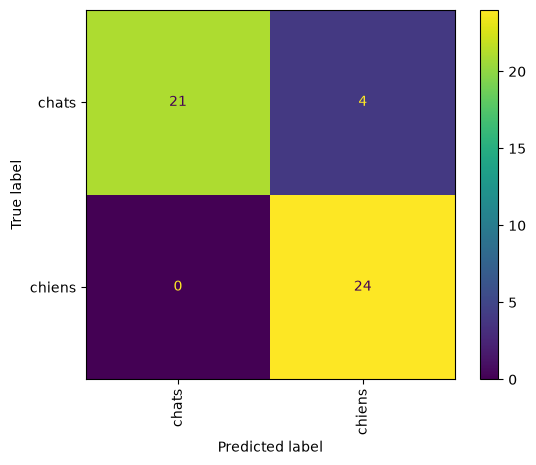

In [53]:
#print(len(end_df))

shuffled_dataset = end_df.sample(frac=1, random_state=1234).reset_index(drop=True)

# Filter out rows where 'path' is a directory before splitting
filtered_shuffled_dataset = shuffled_dataset[shuffled_dataset['path'].apply(os.path.isfile)]

#print(len(shuffled_dataset))

dataset_paths = filtered_shuffled_dataset['path'].to_numpy()
dataset_labels = filtered_shuffled_dataset['label'].to_numpy()


#print(dataset_labels)
#LABEL_NAMES = pd.unique(dataset_labels)
print(LABEL_NAMES)

# We need to convert from string labels to integers
label_encoder = LabelEncoder()
label_encoder.fit(dataset_labels)
end_labels = label_encoder.transform(dataset_labels)

end_images = open_images(dataset_paths)

pred = model.predict(end_images)
pred = np.argmax(pred, axis=-1)

end_confusion_matrix = me.confusion_matrix(end_labels, pred, labels=np.arange(len(LABEL_NAMES)))


dim = len(end_confusion_matrix)

for x in range(dim):
    col = 0
    lin = 0
    for y in range(dim) :
      if y != x :
        col += end_confusion_matrix[y][x]
        lin += end_confusion_matrix[x][y]

    TP = end_confusion_matrix[x][x]
    # Handle division by zero for precision and recall
    precision = TP / (TP + col) if (TP + col) != 0 else 0
    recall = TP / (TP + lin) if (TP + lin) != 0 else 0
    fScore = (2 * precision * recall) / (precision + recall) if (precision + recall) != 0 else 0
    print('F-Score', LABEL_NAMES[x].rjust(12), '(' + str(x) + ')', ':', fScore)


confusion_matrix_display = me.ConfusionMatrixDisplay(
    confusion_matrix=end_confusion_matrix,
    display_labels=LABEL_NAMES,
)

confusion_matrix_display.plot(xticks_rotation='vertical')
plt.show()

Display whole images given with prediction and truth:

Summary of Custom Image Classification:
Total Images: 49
Correctly Classified Images: 45
Accuracy: 91.84%



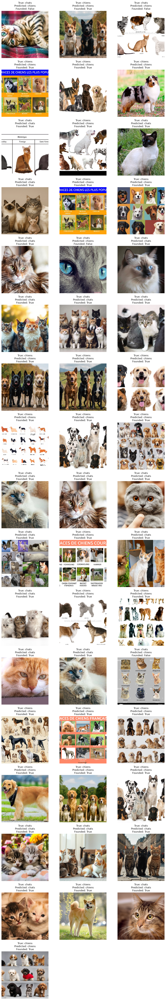

In [52]:
correct_predictions = np.sum(end_labels == pred)
total_images = len(end_labels)

print(f"Summary of Custom Image Classification:")
print(f"Total Images: {total_images}")
print(f"Correctly Classified Images: {correct_predictions}")
print(f"Accuracy: {correct_predictions / total_images:.2%}\n")

# Calculate dynamic grid size
n_cols = 3  # You can adjust the number of columns
n_rows = (total_images + n_cols - 1) // n_cols # Calculate rows needed

plt.figure(figsize=(n_cols * 4, n_rows * 4)) # Adjust figure size dynamically

for i in range(total_images):
    ax = plt.subplot(n_rows, n_cols, i + 1)
    plt.imshow(end_images[i])
    is_same = end_labels[i] == pred[i]
    plt.title(f"True: {LABEL_NAMES[end_labels[i]]}\nPredicted: {LABEL_NAMES[pred[i]]}\nFounded: {is_same}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## Mobile

Adapt for Mobile - https://github.com/SimWalther/TFLClassify

In [ ]:
# Commented out IPython magic to ensure Python compatibility.
%pip install tflite-support
%pip install tflite_support_nightly

In [ ]:

# Commented out IPython magic to ensure Python compatibility.
#%pip install tflite-support
#%pip install tflite_support_nightly
import tensorflow as tf

from tflite_support.metadata_writers import image_classifier
from tflite_support.metadata_writers import writer_utils


# Task Library expects label files that are in the same format as the one below.
LABEL_FILE = "labels.txt"
SAVE_TO_PATH = "MyModel.tflite"

# Create the labels file
with open(LABEL_FILE, 'w') as label_file:
    for label in LABEL_NAMES: # /!\ class_names variable must contains the names of the labels you have.
        label_file.write("{}\n".format(label))

tflite_model = tf.lite.TFLiteConverter.from_keras_model(model).convert()

# Save the model.
with open(SAVE_TO_PATH, 'wb') as f:
    f.write(tflite_model)

ImageClassifierWriter = image_classifier.MetadataWriter

# Normalization parameters is required when reprocessing the image. It is
# optional if the image pixel values are in range of [0, 255] and the input
# tensor is quantized to uint8. See the introduction for normalization and
# quantization parameters below for more details.
# https://www.tensorflow.org/lite/convert/metadata#normalization_and_quantization_parameters)
INPUT_NORM_MEAN = 127.5
INPUT_NORM_STD = 127.5

# Create the metadata writer.
writer = ImageClassifierWriter.create_for_inference(
    writer_utils.load_file(SAVE_TO_PATH),
    [INPUT_NORM_MEAN],
    [INPUT_NORM_STD],
    [LABEL_FILE]
)

# Verify the metadata generated by metadata writer.
print(writer.get_metadata_json())

# Populate the metadata into the model.
writer_utils.save_file(writer.populate(), SAVE_TO_PATH)
